In [741]:
print('In the name of Allah')

In the name of Allah


In [742]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Problem 1:
Scenario:

A data scientist writes the following code:

from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split

df = pd.read_csv('data.csv')

imputer = SimpleImputer(strategy='median')

df[['Age', 'Salary']] = imputer.fit_transform(df[['Age', 'Salary']])

X = df.drop('Target', axis=1)

y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)


Question: Identify the data leakage issue. Explain why it is wrong and write the corrected code.


In [743]:
df = pd.read_csv('data.csv')
df

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Target,Price_Target
0,40.0,9165.0,55361,2.9,NaN,NaN,495310.0,2091,15.1,Dhaka,Unknown,A,NaN,NaN,S,Male,0,280.32
1,33.0,5522.0,48717,NaN,52868.0,1.0,368695.0,1504,28.3,Chittagong,C,C,Type3,NaN,S,Female,1,314.83
2,42.0,50589.0,64787,3.1,79526.0,2.0,453606.0,2052,22.0,Sylhet,A,C,Type1,NaN,C,Female,0,252.43
3,53.0,61289.0,80106,3.6,107581.0,1.0,359753.0,2075,22.7,Rajshahi,C,B,Type2,NaN,S,Female,0,239.21
4,32.0,1604.0,31872,4.0,89654.0,1.0,228869.0,1248,NaN,Rajshahi,A,C,Type2,NaN,S,Female,0,179.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,31.0,16472.0,50253,3.2,82289.0,4.0,NaN,1832,17.0,Dhaka,A,C,Type1,NaN,C,Female,0,309.92
996,56.0,11596.0,41951,2.7,32733.0,2.0,NaN,1127,17.0,Sylhet,A,C,Type1,Cabin_D,S,Male,0,222.41
997,42.0,NaN,44369,2.6,50537.0,2.0,346644.0,1654,24.7,Rajshahi,C,B,Type2,NaN,S,Female,0,221.89
998,NaN,276.0,52691,3.9,143880.0,4.0,307904.0,1908,Unknown,Rajshahi,B,B,NaN,NaN,Q,Female,0,293.69


In [744]:
imputer = SimpleImputer(strategy='median')
df[['Age', 'Salary']] = imputer.fit_transform(df[['Age', 'Salary']])
X = df.drop('Target', axis=1)
y = df['Target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)



> imputer.fit_transform(df[['Age', 'Salary']])



The imputer is being fitted on the entire dataset before train-test split.

This means the imputer learns the median values using both:

1. Training data
2. Test data

So, information from the test set leaks into the training process.

## Why is this wrong?

The test set should remain completely unseen during preprocessing and training.

When the imputer calculates the median using the full dataset, the model indirectly gains knowledge about the test data distribution. This can produce unrealistically good model performance.

In [745]:
df.isnull().sum()

,0
Age,0
Income,150
Salary,0
Rating,80
Annual_Income,120
Customer_Support_Calls,80
House_Price,100
Square_Feet,0
Temperature,50
City,50


In [746]:
X = df.drop(['Target'], axis = 1)

X

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Price_Target
0,40.0,9165.0,55361.0,2.9,NaN,NaN,495310.0,2091,15.1,Dhaka,Unknown,A,NaN,NaN,S,Male,280.32
1,33.0,5522.0,48717.0,NaN,52868.0,1.0,368695.0,1504,28.3,Chittagong,C,C,Type3,NaN,S,Female,314.83
2,42.0,50589.0,64787.0,3.1,79526.0,2.0,453606.0,2052,22.0,Sylhet,A,C,Type1,NaN,C,Female,252.43
3,53.0,61289.0,80106.0,3.6,107581.0,1.0,359753.0,2075,22.7,Rajshahi,C,B,Type2,NaN,S,Female,239.21
4,32.0,1604.0,31872.0,4.0,89654.0,1.0,228869.0,1248,NaN,Rajshahi,A,C,Type2,NaN,S,Female,179.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,31.0,16472.0,50253.0,3.2,82289.0,4.0,NaN,1832,17.0,Dhaka,A,C,Type1,NaN,C,Female,309.92
996,56.0,11596.0,41951.0,2.7,32733.0,2.0,NaN,1127,17.0,Sylhet,A,C,Type1,Cabin_D,S,Male,222.41
997,42.0,NaN,44369.0,2.6,50537.0,2.0,346644.0,1654,24.7,Rajshahi,C,B,Type2,NaN,S,Female,221.89
998,34.5,276.0,52691.0,3.9,143880.0,4.0,307904.0,1908,Unknown,Rajshahi,B,B,NaN,NaN,Q,Female,293.69


In [747]:
y = df['Target']

y

,Target
0,0
1,1
2,0
3,0
4,0
...,...
995,0
996,0
997,0
998,0


In [748]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)


In [749]:
X_train
display(y_train)

,Target
29,0
535,0
695,0
557,0
836,0
...,...
106,0
270,0
860,0
435,0


In [750]:
X_test
display(y_test)

,Target
521,0
737,0
740,0
660,0
411,0
...,...
408,0
332,0
208,0
613,0


In [751]:
X_train.isnull().sum()

,0
Age,0
Income,126
Salary,0
Rating,66
Annual_Income,97
Customer_Support_Calls,62
House_Price,83
Square_Feet,0
Temperature,42
City,38


In [752]:
imputer = SimpleImputer(strategy='median')

In [753]:
X_train[['Age', 'Salary']] = imputer.fit_transform(X_train[['Age', 'Salary']])

X_test[['Age', 'Salary']] = imputer.transform(X_test[['Age', 'Salary']])

In [754]:
# Final version

X = df.drop(['Target'], axis = 1)
y = df['Target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
X_train.isnull().sum()
imputer = SimpleImputer(strategy='median')
X_train[['Age', 'Salary']] = imputer.fit_transform(X_train[['Age', 'Salary']])

X_test[['Age', 'Salary']] = imputer.transform(X_test[['Age', 'Salary']])

# Problem 2:

Question: Using the provided data.csv file, write code to find:

Total missing values in each column

Percentage of missing values per column

Which columns have more than 50% missing values?


In [755]:
missing_values = df.isnull().sum()

print(f'Total missing values in each column : \n{missing_values}')

missing_percentage = ( missing_values / len(df) ) * 100

print(f'Percentage of Missing Values Per Column : \n{missing_percentage}')

more_than_50 = missing_percentage[missing_percentage > 50]

print(f'Columns with More Than 50% Missing Values :\n{more_than_50}')

Total missing values in each column : 
Age                         0
Income                    150
Salary                      0
Rating                     80
Annual_Income             120
Customer_Support_Calls     80
House_Price               100
Square_Feet                 0
Temperature                50
City                       50
Product_Type                0
Location                    0
Diagnosis                 220
Cabin                     680
Embarked                    2
Gender                      0
Target                      0
Price_Target                0
dtype: int64
Percentage of Missing Values Per Column : 
Age                        0.0
Income                    15.0
Salary                     0.0
Rating                     8.0
Annual_Income             12.0
Customer_Support_Calls     8.0
House_Price               10.0
Square_Feet                0.0
Temperature                5.0
City                       5.0
Product_Type               0.0
Location                

# Problem 3:

Question: Look at the Temperature column in data.csv. It contains:

Numeric values like 22.5, 18.6

String 'Unknown'

NaN values

Write code to handle this column properly before imputation.


In [756]:
df['Temperature'].isnull().sum()
df['Temperature'].sample(10)

,Temperature
505,29.5
293,Unknown
878,24.1
811,20.9
594,23.5
732,26.6
989,23.5
204,25.6
595,30.1
735,17.7


In [757]:
df['Temperature'] = df['Temperature'].replace('Unknown', np.nan)

df['Temperature'].sample(10)
df['Temperature'].isnull().sum()

np.int64(115)

In [758]:
df['Temperature'] = pd.to_numeric(df['Temperature'], errors = 'coerce')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     1000 non-null   float64
 1   Income                  850 non-null    float64
 2   Salary                  1000 non-null   float64
 3   Rating                  920 non-null    float64
 4   Annual_Income           880 non-null    float64
 5   Customer_Support_Calls  920 non-null    float64
 6   House_Price             900 non-null    float64
 7   Square_Feet             1000 non-null   int64  
 8   Temperature             885 non-null    float64
 9   City                    950 non-null    object 
 10  Product_Type            1000 non-null   object 
 11  Location                1000 non-null   object 
 12  Diagnosis               780 non-null    object 
 13  Cabin                   320 non-null    object 
 14  Embarked                998 non-null    o

In [759]:
df['Temperature'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 1000 entries, 0 to 999
Series name: Temperature
Non-Null Count  Dtype  
--------------  -----  
885 non-null    float64
dtypes: float64(1)
memory usage: 7.9 KB


In [760]:
# Final Answer

print(f"Column Type: {df['Temperature'].dtype}")
print(f"Missing values after handling: {df['Temperature'].isnull().sum()}")

Column Type: float64
Missing values after handling: 115


# Problem 4:

Question: For the Diagnosis column in data.csv, implement imputation with:

Constant strategy using 'Missing' string

Add a missing indicator column

Write the complete code using SimpleImputer.


In [761]:
X_train.isnull().sum()

,0
Age,0
Income,126
Salary,0
Rating,66
Annual_Income,97
Customer_Support_Calls,62
House_Price,83
Square_Feet,0
Temperature,42
City,38


In [762]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 800 entries, 29 to 102
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     800 non-null    float64
 1   Income                  674 non-null    float64
 2   Salary                  800 non-null    float64
 3   Rating                  734 non-null    float64
 4   Annual_Income           703 non-null    float64
 5   Customer_Support_Calls  738 non-null    float64
 6   House_Price             717 non-null    float64
 7   Square_Feet             800 non-null    int64  
 8   Temperature             758 non-null    object 
 9   City                    762 non-null    object 
 10  Product_Type            800 non-null    object 
 11  Location                800 non-null    object 
 12  Diagnosis               619 non-null    object 
 13  Cabin                   255 non-null    object 
 14  Embarked                798 non-null    object

In [763]:
X_test.isnull().sum()

,0
Age,0
Income,24
Salary,0
Rating,14
Annual_Income,23
Customer_Support_Calls,18
House_Price,17
Square_Feet,0
Temperature,8
City,12


In [764]:
X_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 200 entries, 521 to 78
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     200 non-null    float64
 1   Income                  176 non-null    float64
 2   Salary                  200 non-null    float64
 3   Rating                  186 non-null    float64
 4   Annual_Income           177 non-null    float64
 5   Customer_Support_Calls  182 non-null    float64
 6   House_Price             183 non-null    float64
 7   Square_Feet             200 non-null    int64  
 8   Temperature             192 non-null    object 
 9   City                    188 non-null    object 
 10  Product_Type            200 non-null    object 
 11  Location                200 non-null    object 
 12  Diagnosis               161 non-null    object 
 13  Cabin                   65 non-null     object 
 14  Embarked                200 non-null    object

In [765]:
X_train
display(X_test)

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Price_Target
521,41.0,73315.0,57252.0,3.8,93298.0,4.0,157109.0,2215,20.8,Dhaka,Unknown,A,Type1,NaN,S,Male,223.00
737,46.0,178787.0,55297.0,4.8,126876.0,0.0,419358.0,1092,28.7,Dhaka,C,A,Type2,NaN,S,Female,233.71
740,34.5,6057.0,66301.0,3.3,40303.0,1.0,314431.0,2628,21.9,Dhaka,Unknown,C,Type1,NaN,C,Female,256.23
660,28.0,51440.0,64413.0,3.4,NaN,2.0,270048.0,2261,25.5,Chittagong,Unknown,B,Type2,NaN,C,Male,236.42
411,21.0,12169.0,60287.0,2.0,35858.0,0.0,NaN,1717,22.0,Chittagong,A,C,Type3,NaN,S,Male,322.29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
408,36.0,28947.0,62845.0,2.3,15326.0,2.0,267695.0,2301,29.7,Dhaka,B,B,Type2,NaN,S,Male,217.31
332,35.0,5083.0,21564.0,4.3,63630.0,3.0,428279.0,2197,21.9,Khulna,C,A,Type1,Cabin_C,S,Male,298.54
208,41.0,23917.0,65271.0,2.7,NaN,0.0,387398.0,2418,21.3,Dhaka,A,A,Type1,Cabin_A,S,Female,244.72
613,21.0,8060.0,61040.0,3.2,98569.0,NaN,98509.0,2784,24.4,Chittagong,B,B,Type1,NaN,S,Male,192.67


In [766]:
y_train

display(y_test)

,Target
521,0
737,0
740,0
660,0
411,0
...,...
408,0
332,0
208,0
613,0


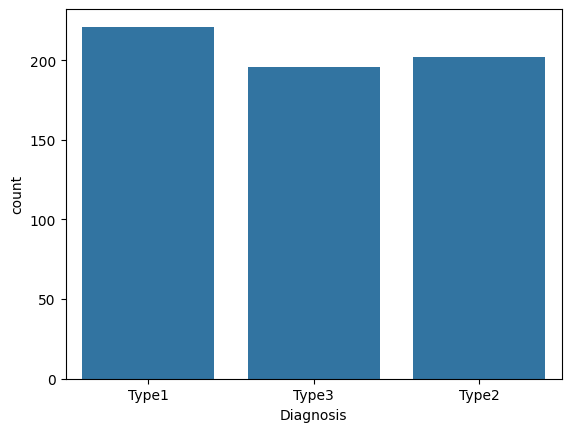

In [767]:
sns.countplot(data = X_train, x = X_train['Diagnosis'])

plt.show()

In [768]:
diagnosis_imputer = SimpleImputer(missing_values = np.nan, strategy = 'constant', fill_value = 'Missing', add_indicator = True)

diagnosis_imputer.fit(X_train[['Diagnosis']])

X_train[['Diagnosis', 'diagnosis_missing_indicator']] = diagnosis_imputer.transform(X_train[['Diagnosis']])

X_test[['Diagnosis', 'diagnosis_missing_indicator']] = diagnosis_imputer.transform(X_test[['Diagnosis']])

In [769]:
X_train

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Price_Target,diagnosis_missing_indicator
29,34.5,20541.0,46632.0,4.2,30172.0,1.0,111387.0,1866,32.5,Chittagong,B,B,Type1,NaN,S,Male,231.94,False
535,35.0,46050.0,71684.0,2.8,72318.0,2.0,289801.0,2067,28.2,Dhaka,B,B,Missing,NaN,Q,Female,228.30,True
695,31.0,8652.0,85790.0,1.4,NaN,4.0,227513.0,1812,24.2,NaN,C,C,Missing,NaN,C,Male,266.84,True
557,29.0,93707.0,52109.0,4.5,100627.0,1.0,191999.0,1510,24.5,Dhaka,A,B,Missing,NaN,S,Female,221.75,True
836,53.0,41021.0,61257.0,1.9,52816.0,1.0,106457.0,1438,21.8,Sylhet,B,C,Missing,NaN,S,Female,261.28,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,57.0,1868.0,53454.0,4.1,55001.0,3.0,NaN,1115,27.2,Chittagong,A,A,Type1,NaN,S,Female,161.48,False
270,52.0,55063.0,52856.0,3.1,111554.0,2.0,162436.0,2028,23.6,Sylhet,B,A,Missing,NaN,C,Female,303.58,True
860,37.0,7655.0,54442.0,3.7,40181.0,5.0,231088.0,1142,21.6,Chittagong,Unknown,A,Type1,NaN,S,Female,327.19,False
435,35.0,48894.0,50286.0,4.1,96119.0,3.0,NaN,1722,24.5,Chittagong,A,A,Type2,NaN,S,Male,311.50,False


In [770]:
X_train

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Price_Target,diagnosis_missing_indicator
29,34.5,20541.0,46632.0,4.2,30172.0,1.0,111387.0,1866,32.5,Chittagong,B,B,Type1,NaN,S,Male,231.94,False
535,35.0,46050.0,71684.0,2.8,72318.0,2.0,289801.0,2067,28.2,Dhaka,B,B,Missing,NaN,Q,Female,228.30,True
695,31.0,8652.0,85790.0,1.4,NaN,4.0,227513.0,1812,24.2,NaN,C,C,Missing,NaN,C,Male,266.84,True
557,29.0,93707.0,52109.0,4.5,100627.0,1.0,191999.0,1510,24.5,Dhaka,A,B,Missing,NaN,S,Female,221.75,True
836,53.0,41021.0,61257.0,1.9,52816.0,1.0,106457.0,1438,21.8,Sylhet,B,C,Missing,NaN,S,Female,261.28,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,57.0,1868.0,53454.0,4.1,55001.0,3.0,NaN,1115,27.2,Chittagong,A,A,Type1,NaN,S,Female,161.48,False
270,52.0,55063.0,52856.0,3.1,111554.0,2.0,162436.0,2028,23.6,Sylhet,B,A,Missing,NaN,C,Female,303.58,True
860,37.0,7655.0,54442.0,3.7,40181.0,5.0,231088.0,1142,21.6,Chittagong,Unknown,A,Type1,NaN,S,Female,327.19,False
435,35.0,48894.0,50286.0,4.1,96119.0,3.0,NaN,1722,24.5,Chittagong,A,A,Type2,NaN,S,Male,311.50,False


In [771]:
X_train.isnull().sum()

,0
Age,0
Income,126
Salary,0
Rating,66
Annual_Income,97
Customer_Support_Calls,62
House_Price,83
Square_Feet,0
Temperature,42
City,38


In [772]:
X_test

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Price_Target,diagnosis_missing_indicator
521,41.0,73315.0,57252.0,3.8,93298.0,4.0,157109.0,2215,20.8,Dhaka,Unknown,A,Type1,NaN,S,Male,223.00,False
737,46.0,178787.0,55297.0,4.8,126876.0,0.0,419358.0,1092,28.7,Dhaka,C,A,Type2,NaN,S,Female,233.71,False
740,34.5,6057.0,66301.0,3.3,40303.0,1.0,314431.0,2628,21.9,Dhaka,Unknown,C,Type1,NaN,C,Female,256.23,False
660,28.0,51440.0,64413.0,3.4,NaN,2.0,270048.0,2261,25.5,Chittagong,Unknown,B,Type2,NaN,C,Male,236.42,False
411,21.0,12169.0,60287.0,2.0,35858.0,0.0,NaN,1717,22.0,Chittagong,A,C,Type3,NaN,S,Male,322.29,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
408,36.0,28947.0,62845.0,2.3,15326.0,2.0,267695.0,2301,29.7,Dhaka,B,B,Type2,NaN,S,Male,217.31,False
332,35.0,5083.0,21564.0,4.3,63630.0,3.0,428279.0,2197,21.9,Khulna,C,A,Type1,Cabin_C,S,Male,298.54,False
208,41.0,23917.0,65271.0,2.7,NaN,0.0,387398.0,2418,21.3,Dhaka,A,A,Type1,Cabin_A,S,Female,244.72,False
613,21.0,8060.0,61040.0,3.2,98569.0,NaN,98509.0,2784,24.4,Chittagong,B,B,Type1,NaN,S,Male,192.67,False


In [773]:
X_test.isnull().sum()

,0
Age,0
Income,24
Salary,0
Rating,14
Annual_Income,23
Customer_Support_Calls,18
House_Price,17
Square_Feet,0
Temperature,8
City,12


# Problem 5:

Question: Using the Age column from data.csv:

Calculate mean and median from training data only

Create two new columns: Age_mean_imputed and Age_median_imputed

Plot KDE for both to compare distributions

Which one would you choose and why?


In [774]:
df.isnull().sum()

,0
Age,0
Income,150
Salary,0
Rating,80
Annual_Income,120
Customer_Support_Calls,80
House_Price,100
Square_Feet,0
Temperature,115
City,50


In [775]:
df['Age'].isnull().sum()

np.int64(0)

In [776]:
X = df.drop(['Target'], axis = 1) # Feature

X

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Price_Target
0,40.0,9165.0,55361.0,2.9,NaN,NaN,495310.0,2091,15.1,Dhaka,Unknown,A,NaN,NaN,S,Male,280.32
1,33.0,5522.0,48717.0,NaN,52868.0,1.0,368695.0,1504,28.3,Chittagong,C,C,Type3,NaN,S,Female,314.83
2,42.0,50589.0,64787.0,3.1,79526.0,2.0,453606.0,2052,22.0,Sylhet,A,C,Type1,NaN,C,Female,252.43
3,53.0,61289.0,80106.0,3.6,107581.0,1.0,359753.0,2075,22.7,Rajshahi,C,B,Type2,NaN,S,Female,239.21
4,32.0,1604.0,31872.0,4.0,89654.0,1.0,228869.0,1248,NaN,Rajshahi,A,C,Type2,NaN,S,Female,179.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,31.0,16472.0,50253.0,3.2,82289.0,4.0,NaN,1832,17.0,Dhaka,A,C,Type1,NaN,C,Female,309.92
996,56.0,11596.0,41951.0,2.7,32733.0,2.0,NaN,1127,17.0,Sylhet,A,C,Type1,Cabin_D,S,Male,222.41
997,42.0,NaN,44369.0,2.6,50537.0,2.0,346644.0,1654,24.7,Rajshahi,C,B,Type2,NaN,S,Female,221.89
998,34.5,276.0,52691.0,3.9,143880.0,4.0,307904.0,1908,NaN,Rajshahi,B,B,NaN,NaN,Q,Female,293.69


In [777]:
y = df['Target'] # Target Column

y

,Target
0,0
1,1
2,0
3,0
4,0
...,...
995,0
996,0
997,0
998,0


In [778]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)


In [779]:
X_train

display(y_train)

,Target
29,0
535,0
695,0
557,0
836,0
...,...
106,0
270,0
860,0
435,0


In [780]:
X_test

display(y_test)

,Target
521,0
737,0
740,0
660,0
411,0
...,...
408,0
332,0
208,0
613,0


In [781]:
X_train.isnull().sum()

,0
Age,0
Income,126
Salary,0
Rating,66
Annual_Income,97
Customer_Support_Calls,62
House_Price,83
Square_Feet,0
Temperature,99
City,38


In [782]:
X_test.isnull().sum()

,0
Age,0
Income,24
Salary,0
Rating,14
Annual_Income,23
Customer_Support_Calls,18
House_Price,17
Square_Feet,0
Temperature,16
City,12


In [783]:
# mean impute

age_mean = X_train['Age'].mean()

age_mean

np.float64(34.610625)

In [784]:
# median impute

age_median = X_train['Age'].median()

age_median

34.5

In [785]:
X_train['age_mean_imputer'] = X_train['Age'].fillna(age_mean)

X_test['age_mean_imputer'] = X_test['Age'].fillna(age_mean)


X_train['age_median_imputer'] = X_train['Age'].fillna(age_median)

X_test['age_median_imputer'] = X_test['Age'].fillna(age_median)

In [786]:
X_train

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Price_Target,age_mean_imputer,age_median_imputer
29,34.5,20541.0,46632.0,4.2,30172.0,1.0,111387.0,1866,32.5,Chittagong,B,B,Type1,NaN,S,Male,231.94,34.5,34.5
535,35.0,46050.0,71684.0,2.8,72318.0,2.0,289801.0,2067,28.2,Dhaka,B,B,NaN,NaN,Q,Female,228.30,35.0,35.0
695,31.0,8652.0,85790.0,1.4,NaN,4.0,227513.0,1812,24.2,NaN,C,C,NaN,NaN,C,Male,266.84,31.0,31.0
557,29.0,93707.0,52109.0,4.5,100627.0,1.0,191999.0,1510,24.5,Dhaka,A,B,NaN,NaN,S,Female,221.75,29.0,29.0
836,53.0,41021.0,61257.0,1.9,52816.0,1.0,106457.0,1438,21.8,Sylhet,B,C,NaN,NaN,S,Female,261.28,53.0,53.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,57.0,1868.0,53454.0,4.1,55001.0,3.0,NaN,1115,27.2,Chittagong,A,A,Type1,NaN,S,Female,161.48,57.0,57.0
270,52.0,55063.0,52856.0,3.1,111554.0,2.0,162436.0,2028,23.6,Sylhet,B,A,NaN,NaN,C,Female,303.58,52.0,52.0
860,37.0,7655.0,54442.0,3.7,40181.0,5.0,231088.0,1142,21.6,Chittagong,Unknown,A,Type1,NaN,S,Female,327.19,37.0,37.0
435,35.0,48894.0,50286.0,4.1,96119.0,3.0,NaN,1722,24.5,Chittagong,A,A,Type2,NaN,S,Male,311.50,35.0,35.0


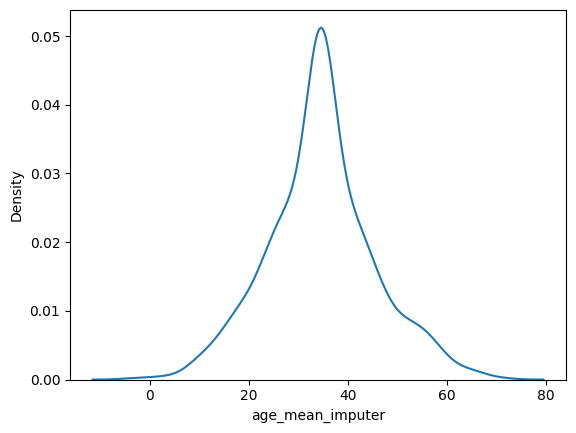

In [787]:
sns.kdeplot(data = X_train, x = 'age_mean_imputer')

plt.show()

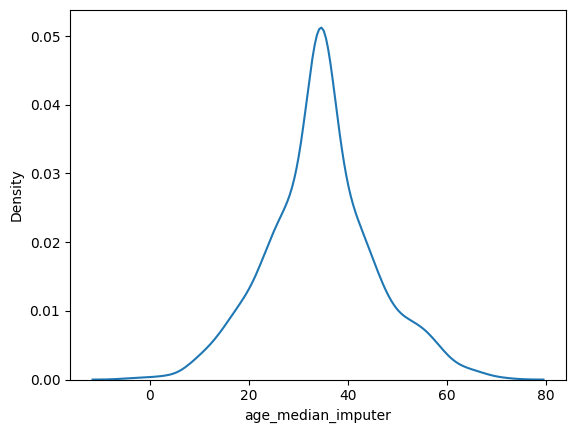

In [788]:
sns.kdeplot(data = X_train, x = 'age_median_imputer')

plt.show()

In [789]:
skew_value = X_train['Age'].skew()

skew_value

np.float64(0.1290033665995715)

Imputation Choice & Justification
Choice: Mean Imputation

Why:

Near-Symmetric Distribution: The Age column has a very low skewness of 0.129, indicating the data is well-balanced and lacks significant outliers that would pull the mean away from the center.

Similarity of Values: Because the distribution is nearly symmetric, the Mean (34.63) and Median (34.00) are almost identical. This means both methods have a nearly identical impact on the dataset's distribution.

Standard Practice: Mean imputation is the standard approach for normally distributed or symmetric data, while median imputation is typically reserved for cases with high skewness or extreme outliers.

In [790]:
age_imputer = SimpleImputer(missing_values = np.nan, strategy = 'mean')

age_imputer.fit(X_train[['Age']])

X_train['Age'] = age_imputer.transform(X_train[['Age']]).ravel()

In [791]:
X_train.isnull().sum()

X_train.drop(['age_mean_imputer', 'age_median_imputer'], axis = 1, inplace = True)


In [792]:
X_train.sample(10)

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Price_Target
69,34.5,NaN,49940.0,3.1,NaN,3.0,362490.0,1526,18.4,Khulna,A,B,Type1,NaN,S,Male,215.83
112,35.0,NaN,68413.0,3.3,NaN,4.0,251634.0,1728,17.0,Dhaka,B,B,Type1,Cabin_D,S,Male,256.06
169,34.5,2470.0,80616.0,4.9,59715.0,1.0,294919.0,3092,19.4,Chittagong,B,C,Type1,NaN,S,Female,192.59
487,22.0,50695.0,60512.0,NaN,48006.0,3.0,347050.0,2963,21.9,Khulna,B,C,Type2,NaN,S,Male,313.23
607,20.0,1797.0,50249.0,3.4,NaN,3.0,364189.0,2429,28.9,Rajshahi,Unknown,A,Type3,NaN,C,Male,275.50
24,28.0,14191.0,52754.0,3.4,50153.0,1.0,222062.0,1735,21.8,Dhaka,A,B,Type1,NaN,S,Male,266.42
722,34.5,NaN,39733.0,3.9,NaN,3.0,261388.0,1632,20.2,Sylhet,C,B,Type1,Cabin_F,C,Female,310.99
993,26.0,10913.0,67191.0,3.4,-4417.0,2.0,182258.0,1435,25.7,Dhaka,Unknown,A,Type2,NaN,S,Male,304.25
116,34.0,15718.0,77596.0,3.0,116726.0,2.0,437461.0,1764,28.0,Khulna,Unknown,C,NaN,NaN,S,Male,238.78
514,28.0,53985.0,75779.0,3.8,64410.0,4.0,235984.0,2205,NaN,Rajshahi,A,A,Type1,Cabin_G,S,Male,139.13


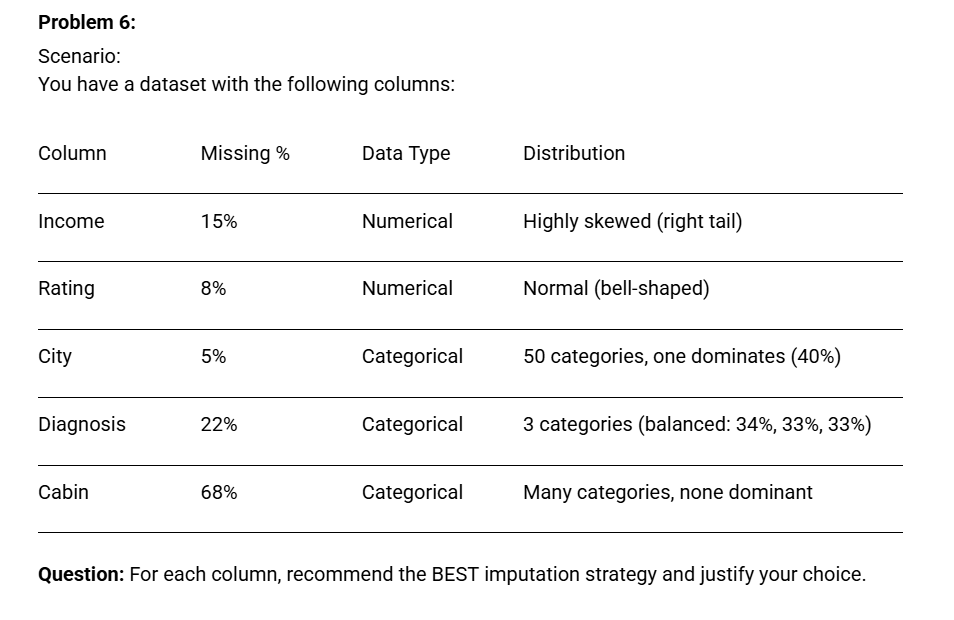

For the **Income** column, we can see that 15% of the values are missing and the distribution is highly skewed. In this case, we should use the **median** for imputation instead of the mean, as it is more robust against the right-tail skew.

For the **Rating** column, which has 8% missing numerical data and a normal distribution, either the **mean** or the median would work effectively.

Moving on to the **City** column, there is a 5% missing rate in a categorical feature where one specific category dominates at 40%. For this scenario, the best strategy is **'most_frequent'** (mode) imputation.

In the **Diagnosis** column, where 22% of the values are missing and the three categories are almost perfectly balanced (around 33-34% each), the best approach is to use a **constant** value (like "Unknown") to avoid biasing the balance.

Finally, for the **Cabin** column, the image shows a missing rate of 68%. Given such a high percentage of missing data in a categorical column with no dominant class, the best option is to **drop the column** entirely.